# Kannada-Hindi Code-Switched Sentiment Analysis

This notebook trains and evaluates baseline sentiment classifiers on a Kannada-Hindi
code-switched text corpus.

**Data note:** No published Kannada-Hindi code-switching dataset exists — the data used
here (`seed_dataset.csv`, `expanded_dataset.csv`, `corpus_broad.csv`) was synthetically
generated via template + lexicon substitution as a bootstrap, and has **not** been
native-speaker verified. Treat results in this notebook as a pipeline demonstration,
not a validated benchmark. See the project README for how to add and validate real data.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score

pd.set_option('display.max_colwidth', 100)
RANDOM_STATE = 42

## 2. Load & merge data

We combine **four** sources:
- `seed_dataset.csv` — 60 hand-written seed sentences (fully synthetic)
- `expanded_dataset.csv` — template-expanded + paraphrase-augmented version of the seed set (fully synthetic)
- `corpus_broad.csv` — a larger, structurally-tagged synthetic corpus (domain / matrix_language / switch_type / polarity)
- `kannada_hindi_pivot_dataset.csv` — **real** Kannada sentences (from DravidianCodeMix Kannada-English
  YouTube comments) with English words substituted for hand-checked Hindi equivalents. This is the only
  source in this dataset with authentic, naturally-occurring Kannada text.

Column names differ across files (`sentiment` vs `polarity` vs `label`), so we normalize to one `label` column.

**Label mapping caveat for the real data**: the pivot dataset's labels are `Positive` / `Negative` /
`Mixed_feelings` (from the original YouTube comment annotation), while our synthetic data uses
`positive` / `negative` / `neutral`. We map `Mixed_feelings` → `neutral` to align the label sets, but
these aren't the same concept — "mixed feelings" means both positive and negative sentiment are present,
while "neutral" means the absence of strong sentiment either way. This is a simplification made for
pipeline compatibility, not a claim that they're equivalent. Keep this in mind when interpreting results
for that class.

In [2]:
seed_df = pd.read_csv('../data/seed_dataset.csv')
expanded_df = pd.read_csv('../data/expanded_dataset.csv')
corpus_df = pd.read_csv('../data/corpus_broad.csv')
pivot_df = pd.read_csv('../data/kannada_hindi_pivot_dataset.csv')

seed_df = seed_df.rename(columns={'sentiment': 'label'})
expanded_df = expanded_df.rename(columns={'sentiment': 'label'})
corpus_df = corpus_df.rename(columns={'polarity': 'label'})

# Normalize the real pivoted data: rename text column, map labels, tag domain/source
pivot_df = pivot_df.rename(columns={'pivoted_text': 'text'})
label_map = {'Positive': 'positive', 'Negative': 'negative', 'Mixed_feelings': 'neutral'}
pivot_df['label'] = pivot_df['label'].map(label_map)
pivot_df['domain'] = 'youtube_comments_real'

seed_df['source_file'] = 'seed'
expanded_df['source_file'] = 'expanded'
corpus_df['source_file'] = 'corpus_broad'
pivot_df['source_file'] = 'real_pivoted'

keep_cols = ['text', 'label', 'domain', 'source_file']
df = pd.concat(
    [seed_df[keep_cols], expanded_df[keep_cols], corpus_df[keep_cols], pivot_df[keep_cols]],
    ignore_index=True
)

# Drop exact duplicate sentences across the combined sources
before = len(df)
df = df.drop_duplicates(subset='text').reset_index(drop=True)
print(f'Rows before dedup: {before}, after dedup: {len(df)}')
df.head()

Rows before dedup: 3641, after dedup: 3494


,text,label,domain,source_file
0,Yeh movie tumba chennagide yaar bahut maza aaya,positive,movies,seed
1,Swalpa adjust madi traffic bahut zyada hai aaji,negative,traffic,seed
2,Idu tumba bad quality item paisa waste ho gaya,negative,shopping,seed
3,Aaj weather chennagide thoda thanda bhi hai,positive,weather,seed
4,Office meeting kaafi lamba tha kelsa hogilla sariyagi,negative,work,seed


## 3. Exploratory data analysis

In [3]:
print('Label distribution:')
print(df['label'].value_counts())
print()
print('Rows per source file:')
print(df['source_file'].value_counts())
print()
is_real = df['source_file'] == 'real_pivoted'
print(f"Real (pivoted) rows: {is_real.sum()} ({is_real.mean():.1%} of total)")
print(f"Synthetic rows:      {(~is_real).sum()} ({(~is_real).mean():.1%} of total)")

Label distribution:
label
positive    1789
negative     926
neutral      779
Name: count, dtype: int64

Rows per source file:
source_file
real_pivoted    1487
corpus_broad    1440
expanded         507
seed              60
Name: count, dtype: int64

Real (pivoted) rows: 1487 (42.6% of total)
Synthetic rows:      2007 (57.4% of total)


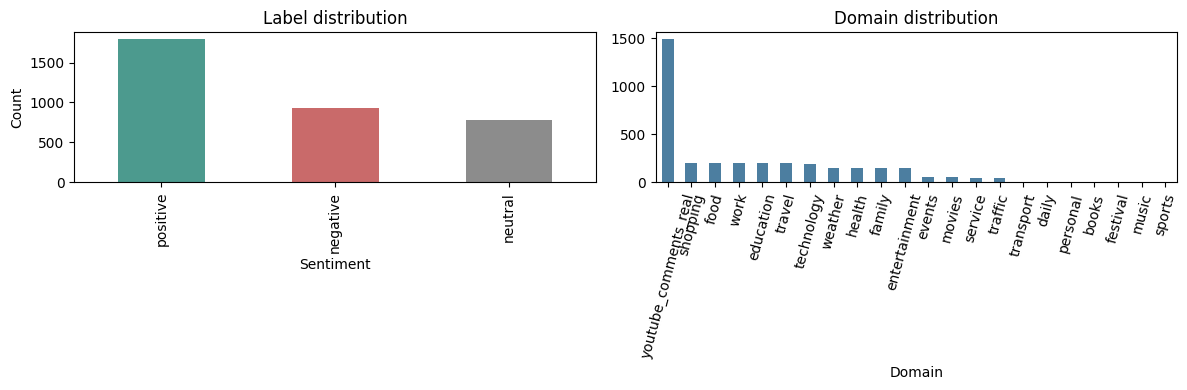

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['label'].value_counts().plot(kind='bar', ax=axes[0], color=['#4C9A8E', '#C96A6A', '#8C8C8C'])
axes[0].set_title('Label distribution')
axes[0].set_xlabel('Sentiment')
axes[0].set_ylabel('Count')

df['domain'].value_counts().plot(kind='bar', ax=axes[1], color='#4C7EA0')
axes[1].set_title('Domain distribution')
axes[1].set_xlabel('Domain')
axes[1].tick_params(axis='x', rotation=75)

plt.tight_layout()
plt.show()

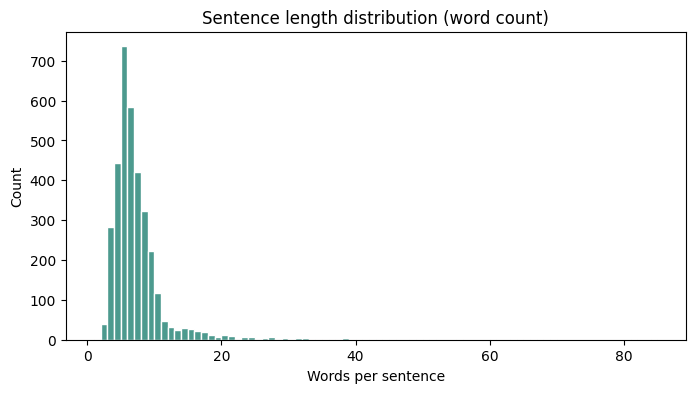

count    3494.000000
mean        7.205781
std         5.928939
min         1.000000
25%         5.000000
50%         6.000000
75%         8.000000
max        84.000000
Name: n_words, dtype: float64


In [5]:
df['n_words'] = df['text'].str.split().apply(len)

plt.figure(figsize=(8, 4))
plt.hist(df['n_words'], bins=range(1, df['n_words'].max() + 2), color='#4C9A8E', edgecolor='white')
plt.title('Sentence length distribution (word count)')
plt.xlabel('Words per sentence')
plt.ylabel('Count')
plt.show()

print(df['n_words'].describe())

## 4. Train / test split

We stratify on `label` to keep class proportions consistent across splits.
Given the synthetic origin of this data, this split checks **pipeline correctness**,
not real-world generalization — a genuinely held-out real-data test set (see README)
is what you'd want before trusting these numbers for anything beyond development.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df['text'], df['label'],
    test_size=0.2, random_state=RANDOM_STATE, stratify=df['label']
)

print(f'Train size: {len(X_train)}, Test size: {len(X_test)}')

Train size: 2795, Test size: 699


## 5. Baseline model: TF-IDF + Logistic Regression

A simple, fast, strong baseline for text classification. TF-IDF works at the word/
character-ngram level, so it doesn't need to 'understand' which language each token
is from — a reasonable starting point for code-mixed text before reaching for
heavier multilingual transformer models.

In [7]:
tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),      # unigrams + bigrams often help catch code-switch bigrams
    min_df=2,
    max_features=5000,
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(f'Vocabulary size: {len(tfidf.vocabulary_)}')

Vocabulary size: 2863


In [8]:
logreg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
logreg.fit(X_train_tfidf, y_train)

y_pred_logreg = logreg.predict(X_test_tfidf)

print('Logistic Regression results:')
print(classification_report(y_test, y_pred_logreg))

Logistic Regression results:
              precision    recall  f1-score   support

    negative       0.93      0.83      0.88       185
     neutral       0.99      0.81      0.89       156
    positive       0.87      0.99      0.92       358

    accuracy                           0.91       699
   macro avg       0.93      0.88      0.90       699
weighted avg       0.91      0.91      0.90       699



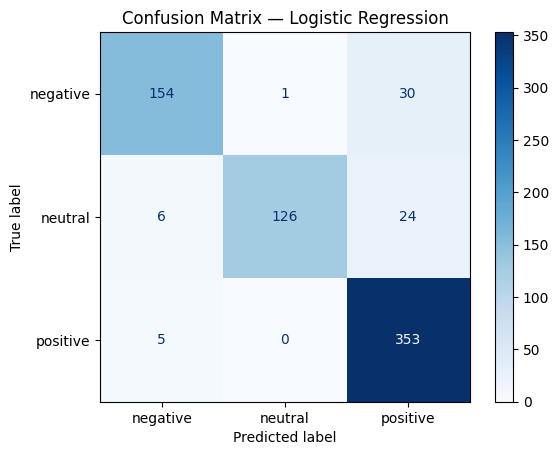

In [9]:
labels_order = sorted(df['label'].unique())
cm = confusion_matrix(y_test, y_pred_logreg, labels=labels_order)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_order)
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix — Logistic Regression')
plt.show()

## 6. Realistic evaluation: held out on REAL data only

This is the check that actually matters. The random train/test split above mixes real and
synthetic sentences into both train and test — so the ~100% accuracy up above is inflated
by synthetic sentences being trivially easy (shared templates/lexicon between train and test).

Here we do something stricter: hold out a stratified chunk of the **real (pivoted)** data as
the test set, train on everything else (synthetic + the remaining real data), and evaluate
*only* on real sentences the model has never seen. This tells us how the model actually
performs on authentic Kannada-Hindi text, not on synthetic lookalikes.

In [10]:
real_df = df[df['source_file'] == 'real_pivoted'].reset_index(drop=True)
synthetic_df = df[df['source_file'] != 'real_pivoted'].reset_index(drop=True)

print(f'Real rows: {len(real_df)}, Synthetic rows: {len(synthetic_df)}')
print()
print('Real data label distribution:')
print(real_df['label'].value_counts())

Real rows: 1487, Synthetic rows: 2007

Real data label distribution:
label
positive    1101
negative     261
neutral      125
Name: count, dtype: int64


In [11]:
# Hold out 30% of the REAL data as a true test set, stratified by label
real_train, real_test = train_test_split(
    real_df, test_size=0.3, random_state=RANDOM_STATE, stratify=real_df['label']
)

# Train on ALL synthetic data + the remaining 70% of real data
train_pool = pd.concat([synthetic_df, real_train], ignore_index=True)

print(f'Train pool: {len(train_pool)} (synthetic: {len(synthetic_df)}, real: {len(real_train)})')
print(f'Real-only held-out test: {len(real_test)}')

Train pool: 3047 (synthetic: 2007, real: 1040)


Real-only held-out test: 447


In [12]:
tfidf_real_eval = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_features=5000)

X_train_pool_tfidf = tfidf_real_eval.fit_transform(train_pool['text'])
X_real_test_tfidf = tfidf_real_eval.transform(real_test['text'])

logreg_real_eval = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
logreg_real_eval.fit(X_train_pool_tfidf, train_pool['label'])

y_pred_real = logreg_real_eval.predict(X_real_test_tfidf)

print('Logistic Regression, evaluated ONLY on held-out real data:')
print(classification_report(real_test['label'], y_pred_real))
print(f"Accuracy: {accuracy_score(real_test['label'], y_pred_real):.1%}")

Logistic Regression, evaluated ONLY on held-out real data:
              precision    recall  f1-score   support

    negative       0.71      0.46      0.56        78
     neutral       1.00      0.03      0.05        38
    positive       0.82      0.98      0.89       331

    accuracy                           0.81       447
   macro avg       0.84      0.49      0.50       447
weighted avg       0.81      0.81      0.76       447

Accuracy: 80.5%


**Compare this accuracy to the mixed-split accuracy in Section 5.** A meaningful drop here is
expected and healthy — it's the model meeting real, messy, naturally-occurring text instead of
synthetic lookalikes of its own training templates. This number (not the Section 5 number) is
the one worth tracking as you improve the pipeline — e.g. by expanding the pivot lexicon for
more real-data coverage, or moving to a multilingual transformer (Section 9).

**What to actually look at here, beyond the headline accuracy**: check the per-class recall,
not just overall accuracy — if `neutral` recall is much lower than `positive`/`negative` recall,
that's not a modeling failure so much as the label-mapping caveat from Section 2 showing up in
the numbers: `neutral` in the real data is standing in for `Mixed_feelings`, which is a genuinely
harder and rarer class (only ~125 of the 1,487 real rows), and "mixed feelings" text often reads
lexically similar to positive or negative text rather than distinctly neutral. A collapsed
`neutral` recall here is telling you about this dataset's label mismatch and class imbalance,
not just about the model.

## 7. Second baseline: Linear SVM

Linear SVMs are a common strong baseline for high-dimensional sparse text features
like TF-IDF, and worth comparing against logistic regression.

In [13]:
svm = LinearSVC(random_state=RANDOM_STATE)
svm.fit(X_train_tfidf, y_train)

y_pred_svm = svm.predict(X_test_tfidf)

print('Linear SVM results:')
print(classification_report(y_test, y_pred_svm))

Linear SVM results:
              precision    recall  f1-score   support

    negative       0.88      0.85      0.87       185
     neutral       0.96      0.82      0.88       156
    positive       0.89      0.96      0.92       358

    accuracy                           0.90       699
   macro avg       0.91      0.88      0.89       699
weighted avg       0.90      0.90      0.90       699



In [14]:
comparison = pd.DataFrame({
    'model': ['Logistic Regression', 'Linear SVM'],
    'accuracy': [accuracy_score(y_test, y_pred_logreg), accuracy_score(y_test, y_pred_svm)],
    'macro_f1': [f1_score(y_test, y_pred_logreg, average='macro'), f1_score(y_test, y_pred_svm, average='macro')],
})
comparison

,model,accuracy,macro_f1
0,Logistic Regression,0.905579,0.897778
1,Linear SVM,0.898426,0.889701


### ⚠️ Why you'll likely see ~100% accuracy here — and why that's not good news

If both models score at or near perfect accuracy, **don't take that as a strong result.**
It means the model is memorizing lexicon/template artifacts, not learning generalizable
sentiment signal — every sentence was built from the same small set of adjective/filler
phrases (`chennagide`, `kharab hai`, etc.), so a linear model over TF-IDF n-grams can
trivially separate classes by spotting those exact phrases in both train and test.

This is the practical consequence of the synthetic-data limitation flagged earlier:
**a perfect score on this test set tells you nothing about performance on real,
naturally-occurring Kannada-Hindi text.** The moment you evaluate on real sentences that
don't reuse this exact lexicon, accuracy will drop — likely substantially. Use this result
only to confirm the pipeline is wired correctly, not as a claim about model quality.

## 8. Error analysis

Looking at a handful of misclassified examples tells you more than the aggregate
metrics alone — especially with synthetic data, where errors can reveal template
artifacts rather than genuine model weaknesses.

In [15]:
results_df = pd.DataFrame({
    'text': X_test.values,
    'true_label': y_test.values,
    'pred_label': y_pred_logreg,
})

errors = results_df[results_df['true_label'] != results_df['pred_label']]
print(f'{len(errors)} misclassified out of {len(results_df)} test examples ({len(errors)/len(results_df):.1%})')
errors.sample(min(10, len(errors)), random_state=RANDOM_STATE)

66 misclassified out of 699 test examples (9.4%)


,text,true_label,pred_label
563,deewana aagode bayya NiNgE..,positive,negative
665,Nam Kannada Heroes ge Support maadade napasand Kodtiralla Enro Neevu.... sab THE behtareen From...,neutral,positive
7,Movie accha lekin climax .I cried,neutral,positive
454,Prithvi swalpa otte kadme maadkoli ...you look accha as well you need it as an actor...,negative,positive
85,zabardast Anna enu ugiri chanagi,neutral,positive
670,Yes agreed first time keldaga 🤦‍🤦‍🤦‍ ansituu lekin 4-5 keldaga agoitu,neutral,positive
149,Movie na theatre nalli nodokagilla anta aur movie tumba dina odilla anta bejaragtide,neutral,negative
132,Rashmika haters pasand madi,negative,positive
690,Tik tok mad suli makkalige chppali ach hodri sulimakkaliga aur ladies fast chuthu sulimakkalu,negative,positive
308,maaf karna sir nim yella video nan nodidini yeno manku badidu nodona hantha download madidde e v...,neutral,positive


## 9. Next step: multilingual transformer fine-tuning (not run here)

TF-IDF + linear models are a solid baseline, but a multilingual transformer
pretrained on Indian languages (e.g. **MuRIL**, **IndicBERT**, or **XLM-R**) would likely
do better at capturing subword-level structure shared across Kannada and Hindi scripts
and transliterations.

**This sandbox environment can't download pretrained model weights** (no internet access
to huggingface.co), so the fine-tuning code below is provided as a reference to run
locally or on Colab/Kaggle with GPU + internet access — it is not executed in this notebook.

In [16]:
# Reference only — requires: pip install transformers torch datasets
# Uncomment and run in an environment with internet + GPU access.

# from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
# from datasets import Dataset
#
# MODEL_NAME = 'google/muril-base-cased'  # or 'ai4bharat/indic-bert', 'xlm-roberta-base'
#
# label2id = {l: i for i, l in enumerate(sorted(df['label'].unique()))}
# id2label = {i: l for l, i in label2id.items()}
#
# train_ds = Dataset.from_pandas(pd.DataFrame({'text': X_train, 'label': y_train.map(label2id)}))
# test_ds = Dataset.from_pandas(pd.DataFrame({'text': X_test, 'label': y_test.map(label2id)}))
#
# tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
#
# def tokenize(batch):
#     return tokenizer(batch['text'], padding='max_length', truncation=True, max_length=64)
#
# train_ds = train_ds.map(tokenize, batched=True)
# test_ds = test_ds.map(tokenize, batched=True)
#
# model = AutoModelForSequenceClassification.from_pretrained(
#     MODEL_NAME, num_labels=len(label2id), id2label=id2label, label2id=label2id
# )
#
# training_args = TrainingArguments(
#     output_dir='./muril_kn_hi_sentiment',
#     eval_strategy='epoch',
#     per_device_train_batch_size=16,
#     per_device_eval_batch_size=16,
#     num_train_epochs=4,
#     learning_rate=2e-5,
#     weight_decay=0.01,
# )
#
# trainer = Trainer(
#     model=model, args=training_args,
#     train_dataset=train_ds, eval_dataset=test_ds,
# )
# trainer.train()

## 10. Conclusions & next steps

- TF-IDF + linear model baselines run cleanly end-to-end on this data — the pipeline works.
- This version of the project includes a **real** data source (Section 2: `real_pivoted`,
  built by substituting hand-checked Hindi words into authentic Kannada sentences from
  DravidianCodeMix) alongside the synthetic sources. Section 6's held-out-on-real-data
  evaluation is the most trustworthy number in this notebook — treat it as the current
  best estimate of real-world performance, and the Section 5 mixed-split accuracy as an
  inflated pipeline sanity check, not a genuine result.
- Recommended path forward:
  1. Expand `en_hi_lexicon.py` (in `pivot_corpus_from_real_data/`) with more hand-checked
     English→Hindi mappings to increase real-data coverage beyond the current ~42% of
     Latin-script DravidianCodeMix rows.
  2. Collect additional real sentences (YouTube comments, Twitter/X from Karnataka-based
     accounts) and get them annotated by 2+ bilingual speakers, to grow the real-data pool
     beyond what pivoting alone can provide.
  3. Once you have GPU + internet access, fine-tune MuRIL or IndicBERT instead of the
     TF-IDF baseline — multilingual subword models handle Kannada-Hindi transliteration
     variation much better than sparse bag-of-words features. Re-run the Section 6
     real-only evaluation with the transformer to see if it actually improves generalization,
     not just the inflated mixed-split number.
  4. Keep reporting the real-only held-out metric (Section 6) as the headline number in any
     writeup — it's the one that reflects actual usefulness.